In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
np.random.seed(42)

In [54]:
df=pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")

# DATA INSPECTION

In [55]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km',
       'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Delivery_Rating', 'Restaurant_Rating', 'Order_Day', 'Peak_Hour',
       'Profit_Margin'],
      dtype='str')

In [56]:
df.shape

(100000, 25)

In [57]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount         44303 no

In [59]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,49907.0,38.976516,12.372157,18.0,28.00,39.00,50.00,60.0
Delivery_Time_Min,66641.0,127.475923,90.805839,20.0,45.00,120.00,210.00,300.0
Distance_km,66530.0,16.449242,12.256742,1.0,5.47,9.97,27.43,40.0
Order_Value,66673.0,2081.830126,1553.628891,150.0,673.00,1197.00,3494.00,5000.0
Discount_Applied,83285.0,93.936243,108.209904,0.0,20.00,50.00,100.00,300.0
Final_Amount,44303.0,1961.101190,1557.354417,-150.0,559.00,1156.00,3375.00,4980.0
Delivery_Rating,83477.0,2.991531,1.414108,1.0,2.00,3.00,4.00,5.0
Restaurant_Rating,100000.0,4.249680,0.722554,3.0,3.60,4.20,4.90,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5


In [60]:
df.dtypes

Order_ID                   str
Customer_ID                str
Customer_Age           float64
Customer_Gender            str
City                       str
Area                       str
Restaurant_ID              str
Restaurant_Name            str
Cuisine_Type               str
Order_Date                 str
Order_Time                 str
Delivery_Time_Min      float64
Distance_km            float64
Order_Value            float64
Discount_Applied       float64
Final_Amount           float64
Payment_Mode               str
Order_Status               str
Cancellation_Reason        str
Delivery_Partner_ID        str
Delivery_Rating        float64
Restaurant_Rating      float64
Order_Day                  str
Peak_Hour               object
Profit_Margin          float64
dtype: object

In [61]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="mixed", errors="coerce")

In [62]:
df["Order_Date"] = df["Order_Date"].dt.normalize()

In [63]:
for col in ["Order_ID", "Customer_ID", "Restaurant_ID", "Delivery_Partner_ID"]:
    df[col] = df[col].astype("str")


In [64]:
df["Peak_Hour"] = df["Peak_Hour"].astype("boolean")

In [65]:
df["Peak_Hour"] = df["Peak_Hour"].map({True: "Peak", False: "Off-Peak"}).fillna("Unknown")

In [66]:
print(df["Peak_Hour"].value_counts(dropna=False))

Peak_Hour
Off-Peak    33585
Peak        33453
Unknown     32962
Name: count, dtype: int64


In [67]:
for col in ["Customer_Age", "Delivery_Time_Min", "Delivery_Rating"]:
    df[col] = df[col].round().astype("Int64")

In [68]:
df.dtypes

Order_ID                          str
Customer_ID                       str
Customer_Age                    Int64
Customer_Gender                   str
City                              str
Area                              str
Restaurant_ID                     str
Restaurant_Name                   str
Cuisine_Type                      str
Order_Date             datetime64[us]
Order_Time                        str
Delivery_Time_Min               Int64
Distance_km                   float64
Order_Value                   float64
Discount_Applied              float64
Final_Amount                  float64
Payment_Mode                      str
Order_Status                      str
Cancellation_Reason               str
Delivery_Partner_ID               str
Delivery_Rating                 Int64
Restaurant_Rating             float64
Order_Day                         str
Peak_Hour                         str
Profit_Margin                 float64
dtype: object

# DATA CLEANING

In [69]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age           50093
Customer_Gender        24856
City                   16726
Area                   16685
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type           16885
Order_Date              1014
Order_Time              1998
Delivery_Time_Min      33359
Distance_km            33470
Order_Value            33327
Discount_Applied       16715
Final_Amount           55697
Payment_Mode           19911
Order_Status               0
Cancellation_Reason    90969
Delivery_Partner_ID        0
Delivery_Rating        16523
Restaurant_Rating          0
Order_Day                  0
Peak_Hour                  0
Profit_Margin              0
dtype: int64

In [70]:
df.isnull().mean()*100

Order_ID                0.000
Customer_ID             0.000
Customer_Age           50.093
Customer_Gender        24.856
City                   16.726
Area                   16.685
Restaurant_ID           0.000
Restaurant_Name         0.000
Cuisine_Type           16.885
Order_Date              1.014
Order_Time              1.998
Delivery_Time_Min      33.359
Distance_km            33.470
Order_Value            33.327
Discount_Applied       16.715
Final_Amount           55.697
Payment_Mode           19.911
Order_Status            0.000
Cancellation_Reason    90.969
Delivery_Partner_ID     0.000
Delivery_Rating        16.523
Restaurant_Rating       0.000
Order_Day               0.000
Peak_Hour               0.000
Profit_Margin           0.000
dtype: float64

In [71]:
df.duplicated(subset=['Order_ID']).sum()

np.int64(0)

In [72]:
df['Cancellation_Reason'].value_counts()

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64

In [73]:
cancelled = df["Order_Status"] == "Cancelled"
df.loc[cancelled, ["Delivery_Rating", "Delivery_Time_Min"]] = np.nan

In [74]:
df.fillna({'Cancellation_Reason': 'No Cancellation Reason'}, inplace=True)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19,Male,NaN,Central,RES936,Restaurant_29,Chinese,2024-10-20,...,NaN,UPI,Delivered,No Cancellation Reason,DP563,5,4.4,Weekend,Peak,0.13
1,ORD000002,CUST6515,<NA>,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,...,4849.0,COD,Delivered,No Cancellation Reason,DP369,5,4.7,Weekday,Peak,0.48
2,ORD000003,CUST1765,<NA>,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,2024-12-08,...,737.0,Wallet,Delivered,No Cancellation Reason,DP580,4,4.9,Weekend,Peak,0.08
3,ORD000004,CUST2744,<NA>,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,...,NaN,UPI,Cancelled,Late Delivery,DP155,<NA>,3.4,Weekday,Unknown,0.04
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,...,352.0,Card,Delivered,No Cancellation Reason,DP728,2,4.4,Weekend,Off-Peak,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,<NA>,NaN,Mumbai,NaN,RES295,Restaurant_500,Arabian,2024-06-10,...,132.0,Card,Delivered,No Cancellation Reason,DP835,2,4.0,Weekday,Peak,0.17
99996,ORD099997,CUST6158,<NA>,Male,Mumbai,East,RES157,Restaurant_458,Arabian,2024-04-22,...,1078.0,NaN,Delivered,No Cancellation Reason,DP476,4,3.5,Weekday,Off-Peak,-0.15
99997,ORD099998,CUST2155,<NA>,NaN,Delhi,East,RES287,Restaurant_273,NaN,2024-02-23,...,NaN,COD,Cancelled,No Cancellation Reason,DP577,<NA>,4.0,Weekday,Peak,0.47
99998,ORD099999,CUST3015,<NA>,Female,Delhi,North,RES491,Restaurant_241,NaN,2024-12-10,...,NaN,NaN,Delivered,No Cancellation Reason,DP896,<NA>,4.3,Weekday,Unknown,0.44


In [75]:
df.loc[(df["Order_Status"] == "Cancelled") & (df["Cancellation_Reason"] == "No Cancellation Reason"),
       "Cancellation_Reason"] = "Not Specified"

df.loc[(df["Order_Status"] == "Delivered") & (df["Cancellation_Reason"] == "No Cancellation Reason"),
       "Cancellation_Reason"] = "Not Applicable"

In [76]:
df['Cancellation_Reason'].value_counts()

Cancellation_Reason
Not Applicable        84964
Not Specified          6005
Late Delivery          3059
Customer Cancelled     2993
Restaurant Issue       2979
Name: count, dtype: int64

In [77]:
df["Customer_Age"].describe()

count      49907.0
mean     38.976516
std      12.372157
min           18.0
25%           28.0
50%           39.0
75%           50.0
max           60.0
Name: Customer_Age, dtype: Float64

In [78]:
len(df[(df['Customer_Age']<=0)|(df['Customer_Age']>100)])

0

In [79]:
df['Customer_Age'].isnull().sum()

np.int64(50093)

In [80]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].describe()

,Customer_Age
count,49907.0
mean,38.976516
std,12.372157
min,18.0
25%,28.0
50%,39.0
75%,50.0
max,60.0


<Axes: ylabel='Frequency'>

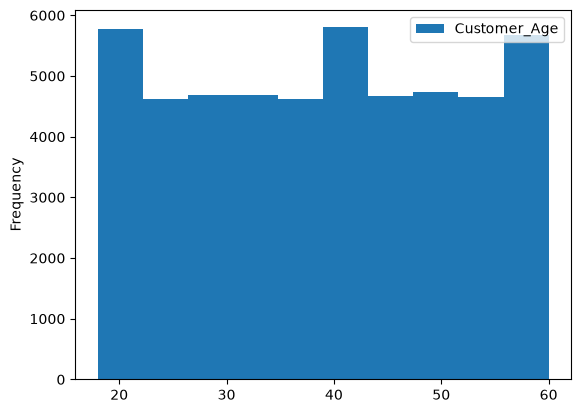

In [81]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].plot(kind='hist')

In [82]:
Proportion=df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].value_counts(normalize=True)
Proportion

Customer_Age
27              0.025247
33              0.025047
49              0.024906
34              0.024205
23              0.024065
53              0.023965
46              0.023965
19              0.023904
56              0.023844
55              0.023744
40              0.023624
44              0.023584
29              0.023524
39              0.023504
48              0.023484
30              0.023363
42              0.023363
36              0.023343
51              0.023303
57              0.023283
38              0.023283
45              0.023263
18              0.023183
37              0.023163
21              0.023123
50              0.023083
25              0.023063
32              0.023003
26              0.022963
43              0.022963
35              0.022923
41              0.022782
54              0.022782
22              0.022762
47              0.022662
20              0.022662
52              0.022622
24              0.022502
59              0.022402
60          

In [83]:
Fill_index=df[(df['Customer_Age'].isnull())|(df['Customer_Age']<=0)|(df['Customer_Age']>100)]['Customer_Age'].index
Fill_index

Index([    1,     2,     3,     7,     8,     9,    10,    11,    12,    13,
       ...
       99985, 99986, 99990, 99991, 99994, 99995, 99996, 99997, 99998, 99999],
      dtype='int64', length=50093)

In [84]:
Proportion.index

MultiIndex([(27,),
            (33,),
            (49,),
            (34,),
            (23,),
            (53,),
            (46,),
            (19,),
            (56,),
            (55,),
            (40,),
            (44,),
            (29,),
            (39,),
            (48,),
            (30,),
            (42,),
            (36,),
            (51,),
            (57,),
            (38,),
            (45,),
            (18,),
            (37,),
            (21,),
            (50,),
            (25,),
            (32,),
            (26,),
            (43,),
            (35,),
            (41,),
            (54,),
            (22,),
            (47,),
            (20,),
            (52,),
            (24,),
            (59,),
            (60,),
            (58,),
            (28,),
            (31,)],
           names=['Customer_Age'])

In [85]:
Proportion.values

array([0.02524696, 0.02504659, 0.02490633, 0.02420502, 0.02406476,
       0.02396457, 0.02396457, 0.02390446, 0.02384435, 0.02374416,
       0.02362394, 0.02358387, 0.02352375, 0.02350372, 0.02348368,
       0.02336346, 0.02336346, 0.02334342, 0.02330334, 0.02328331,
       0.02328331, 0.02326327, 0.02318312, 0.02316308, 0.02312301,
       0.02308293, 0.0230629 , 0.02300279, 0.02296271, 0.02296271,
       0.02292264, 0.02278238, 0.02278238, 0.02276234, 0.02266215,
       0.02266215, 0.02262208, 0.02250185, 0.02240167, 0.02236159,
       0.02196085, 0.0217204 , 0.02149999])

In [86]:
np.random.choice(Proportion.index,len(Fill_index),p=Proportion.values)

array([(30,), (58,), (41,), ..., (24,), (25,), (20,)],
      shape=(50093,), dtype=object)

In [87]:
df.loc[0:10, ["Customer_ID", "Customer_Age"]]

,Customer_ID,Customer_Age
0,CUST6948,19
1,CUST6515,<NA>
2,CUST1765,<NA>
3,CUST2744,<NA>
4,CUST4389,57
5,CUST3161,37
6,CUST2307,40
7,CUST5865,<NA>
8,CUST4356,<NA>
9,CUST2404,<NA>


In [88]:
Proportion = df['Customer_Age'].value_counts(normalize=True)

Fill_index = df.index[df['Customer_Age'].isna()]

df.loc[Fill_index, 'Customer_Age'] = np.random.choice(
    Proportion.index.to_numpy(),
    size=len(Fill_index),
    p=Proportion.values
)

In [89]:
print(df['Customer_Age'].dtype)
print(Proportion.index[:5])    
df['Customer_Age'] = pd.to_numeric(df['Customer_Age'], errors='coerce')

Int64
Index([27, 33, 49, 34, 23], dtype='Int64', name='Customer_Age')


In [90]:
df["Customer_Age"].isnull().sum()

np.int64(0)

<Axes: ylabel='Frequency'>

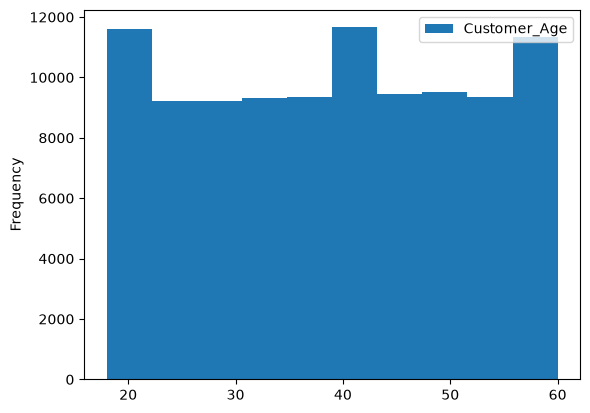

In [91]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].plot(kind='hist')

In [92]:
df["Delivery_Rating"].isnull().sum()

np.int64(29084)

In [93]:
delivered = df["Order_Status"] == "Delivered"
rating_median = df.loc[delivered, "Delivery_Rating"].median()
df.loc[delivered, "Delivery_Rating"] = df.loc[delivered, "Delivery_Rating"].fillna(rating_median)

In [94]:
df['Payment_Mode'].value_counts()

Payment_Mode
Card      20094
Wallet    20086
COD       19977
UPI       19932
Name: count, dtype: int64

In [95]:
df['Payment_Mode'] = df['Payment_Mode'].fillna('Unknown')

In [96]:
df["Discount_Applied"].value_counts()

Discount_Applied
100.0    16776
50.0     16690
0.0      16650
300.0    16600
20.0     16569
Name: count, dtype: int64

In [97]:
df["Discount_Applied"] = df["Discount_Applied"].fillna(0)

df["Discount_Applied"] = df[["Discount_Applied", "Order_Value"]].min(axis=1)

In [98]:
print("Missing Discount:",
      df["Discount_Applied"].isnull().sum())

print("Negative Discount:",
      (df["Discount_Applied"] < 0).sum())

print("Discount > Order Value:",
      (df["Discount_Applied"] > df["Order_Value"]).sum())

Missing Discount: 0
Negative Discount: 0
Discount > Order Value: 0


In [99]:
df[["Order_Value", "Discount_Applied"]].head()

,Order_Value,Discount_Applied
0,NaN,0.0
1,4869.0,20.0
2,757.0,20.0
3,NaN,0.0
4,372.0,20.0


In [100]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].describe()

,Order_Value,Discount_Applied,Final_Amount
count,66673.000000,100000.00000,44303.000000
mean,2081.830126,77.64023,1961.101190
std,1553.628891,103.80528,1557.354417
min,150.000000,0.00000,-150.000000
25%,673.000000,0.00000,559.000000
50%,1197.000000,50.00000,1156.000000
75%,3494.000000,100.00000,3375.000000
max,5000.000000,300.00000,4980.000000


In [101]:
df[df["Final_Amount"] < 0][
    ["Order_Value", "Discount_Applied", "Final_Amount"]
].head(10)

,Order_Value,Discount_Applied,Final_Amount
104,187.0,187.0,-113.0
132,175.0,175.0,-125.0
284,246.0,246.0,-54.0
306,194.0,194.0,-106.0
359,285.0,285.0,-15.0
576,247.0,247.0,-53.0
619,234.0,234.0,-66.0
729,210.0,210.0,-90.0
891,195.0,195.0,-105.0
1148,204.0,204.0,-96.0


In [102]:
df["Discount_Applied"] > df["Order_Value"].sum()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: Discount_Applied, Length: 100000, dtype: bool

In [103]:
df["Final_Amount"].isnull().sum()

np.int64(55697)

In [104]:
df["Cuisine_Type"].value_counts()

Cuisine_Type
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64

In [105]:
df['Cuisine_Type']= df['Cuisine_Type'].fillna('Unknown')

In [106]:
df['Customer_Gender'] = df['Customer_Gender'].fillna('Unknown')
df['Area'] = df['Area'].fillna('Unknown')
df['City'] = df['City'].fillna('Unknown')

In [107]:
df['Customer_Gender'].value_counts()

Customer_Gender
Other      25135
Female     25031
Male       24978
Unknown    24856
Name: count, dtype: int64

In [108]:
df['Delivery_Time_Min'].describe()

count       56635.0
mean     127.466514
std       90.859278
min            20.0
25%            45.0
50%           120.0
75%           210.0
max           300.0
Name: Delivery_Time_Min, dtype: Float64

In [109]:
df.groupby('City')['Delivery_Time_Min'].mean().sort_values(ascending=False)

City
Mumbai       128.648462
Unknown      127.880073
Hyderabad    127.761955
Delhi        127.588748
Bangalore    126.465778
Chennai      126.464118
Name: Delivery_Time_Min, dtype: Float64

In [110]:
delivered = df["Order_Status"] == "Delivered"
delivery_median = df.loc[delivered, "Delivery_Time_Min"].median()
delivered_times = df.loc[delivered].groupby("City")["Delivery_Time_Min"]
df.loc[delivered, "Delivery_Time_Min"] = delivered_times.transform(
    lambda city_times: city_times.fillna(city_times.median())
)
df.loc[delivered, "Delivery_Time_Min"] = df.loc[delivered, "Delivery_Time_Min"].fillna(delivery_median)

In [111]:
df.loc[df["Order_Status"] == "Cancelled", "Delivery_Time_Min"] = np.nan

In [112]:
df.groupby('City')['Distance_km'].mean().sort_values(ascending=False)

City
Mumbai       16.568394
Bangalore    16.556062
Hyderabad    16.463371
Unknown      16.385769
Chennai      16.381938
Delhi        16.340507
Name: Distance_km, dtype: float64

In [113]:
df['Distance_km']=df.groupby('City')['Distance_km'].transform(lambda x:x.fillna(x.mean()))

In [114]:
df["Distance_km"] = df["Distance_km"].round(2)

In [115]:
df['Distance_km'].isnull().sum()

np.int64(0)

In [116]:
df['Order_Value'].describe()

count    66673.000000
mean      2081.830126
std       1553.628891
min        150.000000
25%        673.000000
50%       1197.000000
75%       3494.000000
max       5000.000000
Name: Order_Value, dtype: float64

In [117]:
df['Order_Value']=df["Order_Value"].fillna(
    df["Order_Value"].median()
)

In [118]:
df["Order_Date"].isnull().sum()

np.int64(1014)

In [119]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

In [120]:
common_date=df["Order_Date"].mode().iloc[0]
df["Order_Date"] = df["Order_Date"].fillna(common_date)

In [121]:
abs(df['Final_Amount']).describe()

count    44303.000000
mean      1963.785297
std       1553.968380
min          0.000000
25%        559.000000
50%       1156.000000
75%       3375.000000
max       4980.000000
Name: Final_Amount, dtype: float64

In [122]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].describe()

,Order_Value,Discount_Applied,Final_Amount
count,100000.00000,100000.00000,44303.000000
mean,1786.94279,77.64023,1961.101190
std,1335.39821,103.80528,1557.354417
min,150.00000,0.00000,-150.000000
25%,935.00000,0.00000,559.000000
50%,1197.00000,50.00000,1156.000000
75%,2743.00000,100.00000,3375.000000
max,5000.00000,300.00000,4980.000000


In [123]:
df[df["Final_Amount"] < 0][
    ["Order_Value", "Discount_Applied", "Final_Amount"]
]

,Order_Value,Discount_Applied,Final_Amount
104,187.0,187.0,-113.0
132,175.0,175.0,-125.0
284,246.0,246.0,-54.0
306,194.0,194.0,-106.0
359,285.0,285.0,-15.0
...,...,...,...
99645,225.0,225.0,-75.0
99681,216.0,216.0,-84.0
99870,285.0,285.0,-15.0
99939,184.0,184.0,-116.0


In [124]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].corr()

,Order_Value,Discount_Applied,Final_Amount
Order_Value,1.000000,0.006513,0.997546
Discount_Applied,0.006513,1.000000,-0.051386
Final_Amount,0.997546,-0.051386,1.000000


In [125]:
df[df["Final_Amount"].notna()][
    ["Order_Value", "Discount_Applied", "Final_Amount"]
].head(20)

,Order_Value,Discount_Applied,Final_Amount
1,4869.0,20.0,4849.0
2,757.0,20.0,737.0
4,372.0,20.0,352.0
7,3506.0,20.0,3486.0
8,525.0,100.0,425.0
9,4691.0,50.0,4641.0
10,4881.0,100.0,4781.0
12,417.0,20.0,397.0
14,4017.0,300.0,3717.0
16,4218.0,20.0,4198.0


In [126]:
df[df["Final_Amount"].notna()][
    ["Order_Value", "Discount_Applied", "Final_Amount"]
].tail(20)

,Order_Value,Discount_Applied,Final_Amount
99959,3860.0,50.0,3810.0
99961,174.0,174.0,-126.0
99963,4873.0,100.0,4773.0
99965,872.0,300.0,572.0
99966,166.0,20.0,146.0
99967,296.0,20.0,276.0
99968,4139.0,100.0,4039.0
99969,366.0,50.0,316.0
99971,3581.0,20.0,3561.0
99973,481.0,50.0,431.0


In [127]:
df["Final_Amount"] = df["Order_Value"] - df["Discount_Applied"]

In [128]:
df["Final_Amount"].isnull().sum()

np.int64(0)

In [129]:
known = df[df['Final_Amount'].notna()]
diff = known['Final_Amount'] - (known['Order_Value'] - known['Discount_Applied'])
print((diff == 0).mean())
print(diff.describe())

1.0
count    100000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
dtype: float64


In [130]:
df['Discount_Applied'] = df[['Discount_Applied', 'Order_Value']].min(axis=1)
df['Final_Amount'] = df['Order_Value'] - df['Discount_Applied']

In [131]:
print(df['Final_Amount'].isna().sum())  
print(df['Final_Amount'].min())          
print(df['Discount_Applied'].isna().sum())  

0
0.0
0


In [132]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99463,12.364352,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,119.668942,76.248493,20.0,58.0,120.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,1786.94279,1335.39821,150.0,935.0,1197.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,1709.30256,1338.752465,0.0,856.0,1177.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.24968,0.722554,3.0,3.6,4.2,4.9,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5


In [133]:
df['Final_Amount'].describe()

count    100000.000000
mean       1709.302560
std        1338.752465
min           0.000000
25%         856.000000
50%        1177.000000
75%        2663.000000
max        5000.000000
Name: Final_Amount, dtype: float64

In [134]:
original_discounts = [0, 20, 50, 100, 300]
affected = int((~df["Discount_Applied"].isin(original_discounts)).sum())
pct = round(affected / len(df) * 100, 2)
print(f"{affected} rows ({pct}%)")

773 rows (0.77%)


In [135]:
check = df["Order_Value"] - df["Discount_Applied"]
print("Rows where the formula does not match:", (df["Final_Amount"] != check).sum())
print("Negative final amounts:", (df["Final_Amount"] < 0).sum())
print("Orders with a zero final amount:", (df["Final_Amount"] == 0).sum())

Rows where the formula does not match: 0
Negative final amounts: 0
Orders with a zero final amount: 777


In [136]:
print((df["Order_Value"] == 300).sum())
print(((df["Order_Value"] == 300) & (df["Discount_Applied"] == 300)).sum())

30
4


In [137]:
loss_pct = (df["Profit_Margin"] < 0).mean() * 100
print(f"{loss_pct:.1f}% of orders have negative profit margin")

27.7% of orders have negative profit margin


In [138]:
print((df["Final_Amount"] == 0).sum())

777


In [139]:
df["Is_Loss"] = (df["Profit_Margin"] < 0).astype(int)

print("Loss % by City:")
print((df.groupby("City")["Is_Loss"].mean() * 100).round(1))

print("\nLoss % by Cuisine:")
print((df.groupby("Cuisine_Type")["Is_Loss"].mean() * 100).round(1))

print("\nLoss % by Discount:")
print((df.groupby("Discount_Applied")["Is_Loss"].mean() * 100).round(1).head(8))

Loss % by City:
City
Bangalore    27.8
Chennai      28.1
Delhi        27.6
Hyderabad    27.8
Mumbai       27.7
Unknown      27.3
Name: Is_Loss, dtype: float64

Loss % by Cuisine:
Cuisine_Type
Arabian    27.3
Chinese    28.3
Indian     28.0
Italian    27.7
Mexican    27.6
Unknown    27.5
Name: Is_Loss, dtype: float64

Loss % by Discount:
Discount_Applied
0.0      27.7
20.0     27.9
50.0     28.1
100.0    27.8
150.0     0.0
151.0    28.6
152.0    50.0
153.0    28.6
Name: Is_Loss, dtype: float64


About 27.7% of orders have a negative profit margin, and the loss rate is nearly identical across cities, cuisines and discount levels (27 to 28%). So no single factor explains the losses.

## Handling Negative Values in `Final_Amount`
- **Problem:** `Final_Amount` had negative values (min = -150), which is impossible for a bill.
- **Cause and fix:** `Discount_Applied` was greater than `Order_Value` in some rows, so I capped the discount at the order value and recalculated `Final_Amount = Order_Value - Discount_Applied`.
- **Result:** No nulls and no negatives now, and all 100,000 orders are kept (773 rows, 0.77%, were affected)..

In [140]:
df["Order_Status"].value_counts()

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64

In [141]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
City                       0
Area                       0
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type               0
Order_Date                 0
Order_Time              1998
Delivery_Time_Min      15036
Distance_km                0
Order_Value                0
Discount_Applied           0
Final_Amount               0
Payment_Mode               0
Order_Status               0
Cancellation_Reason        0
Delivery_Partner_ID        0
Delivery_Rating        15036
Restaurant_Rating          0
Order_Day                  0
Peak_Hour                  0
Profit_Margin              0
Is_Loss                    0
dtype: int64

# DATA VALIDATION
Check the cleaned values, data types, ranges, and categories. A validation
check helps catch problems before saving or using the data.

In [142]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99463,12.364352,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,119.668942,76.248493,20.0,58.0,120.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,1786.94279,1335.39821,150.0,935.0,1197.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,1709.30256,1338.752465,0.0,856.0,1177.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.24968,0.722554,3.0,3.6,4.2,4.9,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5
Is_Loss,100000.0,0.27733,0.447683,0.0,0.0,0.0,1.0,1.0


In [143]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Customer_ID          100000 non-null  str           
 2   Customer_Age         100000 non-null  Int64         
 3   Customer_Gender      100000 non-null  str           
 4   City                 100000 non-null  str           
 5   Area                 100000 non-null  str           
 6   Restaurant_ID        100000 non-null  str           
 7   Restaurant_Name      100000 non-null  str           
 8   Cuisine_Type         100000 non-null  str           
 9   Order_Date           100000 non-null  datetime64[us]
 10  Order_Time           98002 non-null   str           
 11  Delivery_Time_Min    84964 non-null   Int64         
 12  Distance_km          100000 non-null  float64       
 13  Order_Value          10000

In [144]:
df.select_dtypes(include='str')

,Order_ID,Customer_ID,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Time,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Order_Day,Peak_Hour
0,ORD000001,CUST6948,Male,Unknown,Central,RES936,Restaurant_29,Chinese,0:00,UPI,Delivered,Not Applicable,DP563,Weekend,Peak
1,ORD000002,CUST6515,Female,Chennai,North,RES689,Restaurant_419,Chinese,0:00,COD,Delivered,Not Applicable,DP369,Weekday,Peak
2,ORD000003,CUST1765,Male,Delhi,Unknown,RES723,Restaurant_244,Arabian,0:00,Wallet,Delivered,Not Applicable,DP580,Weekend,Peak
3,ORD000004,CUST2744,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,0:00,UPI,Cancelled,Late Delivery,DP155,Weekday,Unknown
4,ORD000005,CUST4389,Female,Chennai,South,RES419,Restaurant_262,Chinese,0:00,Card,Delivered,Not Applicable,DP728,Weekend,Off-Peak
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,Unknown,Mumbai,Unknown,RES295,Restaurant_500,Arabian,0:00,Card,Delivered,Not Applicable,DP835,Weekday,Peak
99996,ORD099997,CUST6158,Male,Mumbai,East,RES157,Restaurant_458,Arabian,0:00,Unknown,Delivered,Not Applicable,DP476,Weekday,Off-Peak
99997,ORD099998,CUST2155,Unknown,Delhi,East,RES287,Restaurant_273,Unknown,0:00,COD,Cancelled,Not Specified,DP577,Weekday,Peak
99998,ORD099999,CUST3015,Female,Delhi,North,RES491,Restaurant_241,Unknown,0:00,Unknown,Delivered,Not Applicable,DP896,Weekday,Unknown


In [145]:
df.select_dtypes(include=['int64','int32','int','float','float32','float64'])

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin,Is_Loss
0,19,187,15.75,1197.0,0.0,1197.0,5,4.4,0.13,0
1,54,20,29.50,4869.0,20.0,4849.0,5,4.7,0.48,0
2,46,207,16.34,757.0,20.0,737.0,4,4.9,0.08,0
3,32,<NA>,15.68,1197.0,0.0,1197.0,<NA>,3.4,0.04,0
4,57,51,9.60,372.0,20.0,352.0,2,4.4,0.12,0
...,...,...,...,...,...,...,...,...,...,...
99995,60,122,16.57,232.0,100.0,132.0,2,4.0,0.17,0
99996,54,46,16.57,1098.0,20.0,1078.0,4,3.5,-0.15,1
99997,48,<NA>,18.57,1197.0,20.0,1177.0,<NA>,4.0,0.47,0
99998,25,65,3.77,1197.0,100.0,1097.0,3,4.3,0.44,0


In [146]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Customer_ID          100000 non-null  str           
 2   Customer_Age         100000 non-null  Int64         
 3   Customer_Gender      100000 non-null  str           
 4   City                 100000 non-null  str           
 5   Area                 100000 non-null  str           
 6   Restaurant_ID        100000 non-null  str           
 7   Restaurant_Name      100000 non-null  str           
 8   Cuisine_Type         100000 non-null  str           
 9   Order_Date           100000 non-null  datetime64[us]
 10  Order_Time           98002 non-null   str           
 11  Delivery_Time_Min    84964 non-null   Int64         
 12  Distance_km          100000 non-null  float64       
 13  Order_Value          10000

In [147]:
df.columns = df.columns.str.strip()

In [148]:
text_columns = df.select_dtypes(include="str").columns

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

In [149]:
print(text_columns)

Index(['Order_ID', 'Customer_ID', 'Customer_Gender', 'City', 'Area',
       'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Order_Time',
       'Payment_Mode', 'Order_Status', 'Cancellation_Reason',
       'Delivery_Partner_ID', 'Order_Day', 'Peak_Hour'],
      dtype='str')


In [150]:
numeric_cols = df.select_dtypes(include="number").columns
print(numeric_cols)

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Is_Loss'],
      dtype='str')


In [151]:
df[numeric_cols].describe()

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin,Is_Loss
count,100000.0,84964.0,100000.000000,100000.00000,100000.00000,100000.000000,84964.0,100000.000000,100000.000000,100000.000000
mean,38.99463,119.668942,16.449519,1786.94279,77.64023,1709.302560,2.993268,4.249680,0.150362,0.277330
std,12.364352,76.248493,9.997431,1335.39821,103.80528,1338.752465,1.29254,0.722554,0.201888,0.447683
min,18.0,20.0,1.000000,150.00000,0.00000,0.000000,1.0,3.000000,-0.200000,0.000000
25%,28.0,58.0,7.760000,935.00000,0.00000,856.000000,2.0,3.600000,-0.020000,0.000000
50%,39.0,120.0,16.390000,1197.00000,50.00000,1177.000000,3.0,4.200000,0.150000,0.000000
75%,50.0,165.0,21.130000,2743.00000,100.00000,2663.000000,4.0,4.900000,0.320000,1.000000
max,60.0,300.0,40.000000,5000.00000,300.00000,5000.000000,5.0,5.500000,0.500000,1.000000


In [152]:
categorical_cols = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Cancellation_Reason",
    "Order_Day",
    "Peak_Hour"
]

In [153]:
print("Restaurant rating above 5:", (df["Restaurant_Rating"] > 5).sum())
print("Delivery rating above 5:  ", (df["Delivery_Rating"] > 5).sum())
print("Restaurant rating min/max:", df["Restaurant_Rating"].min(), df["Restaurant_Rating"].max())

Restaurant rating above 5: 18019
Delivery rating above 5:   0
Restaurant rating min/max: 3.0 5.5


In [154]:
print("Before -> max:", df["Restaurant_Rating"].max(), "| rows above 5:", (df["Restaurant_Rating"] > 5).sum())
df["Restaurant_Rating"] = df["Restaurant_Rating"].clip(upper=5)
print("After  -> max:", df["Restaurant_Rating"].max(), "| rows above 5:", (df["Restaurant_Rating"] > 5).sum())

Before -> max: 5.5 | rows above 5: 18019
After  -> max: 5.0 | rows above 5: 0


In [155]:
df[(df["Delivery_Time_Min"] < 20) | (df["Delivery_Time_Min"] > 300)
][["Delivery_Time_Min"]]

,Delivery_Time_Min


In [156]:
df[(df["Distance_km"] < 1) |(df["Distance_km"] > 40)][["Distance_km"]]

,Distance_km


In [157]:
df['Order_Status'].value_counts()

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64

# OUTLIER DETECTION

In [158]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99463,12.364352,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,119.668942,76.248493,20.0,58.0,120.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,1786.94279,1335.39821,150.0,935.0,1197.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,1709.30256,1338.752465,0.0,856.0,1177.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.199779,0.654037,3.0,3.6,4.2,4.9,5.0
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5
Is_Loss,100000.0,0.27733,0.447683,0.0,0.0,0.0,1.0,1.0


<Axes: >

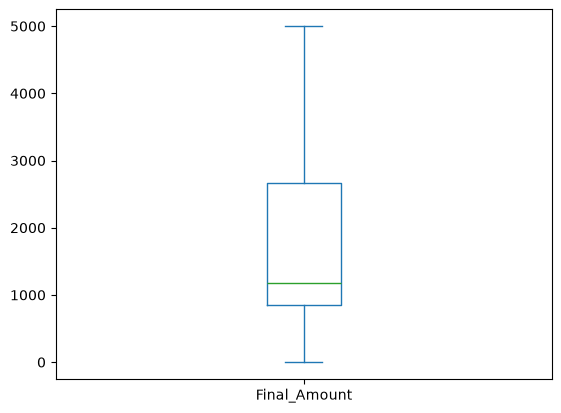

In [159]:
df["Final_Amount"].plot(kind="box")

<Axes: >

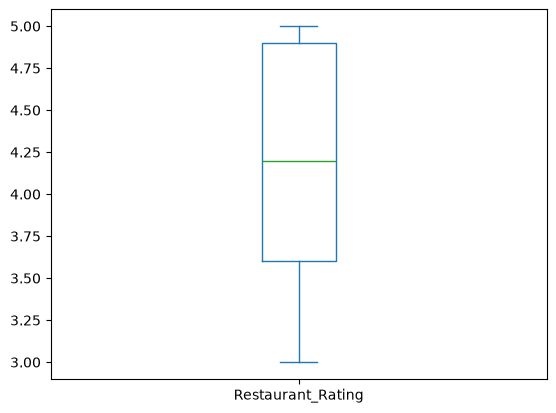

In [160]:
df["Restaurant_Rating"].plot(kind="box")

<Axes: >

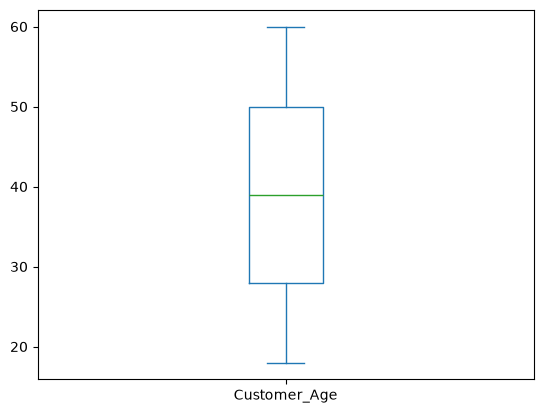

In [161]:
df["Customer_Age"].plot(kind="box")

<Axes: >

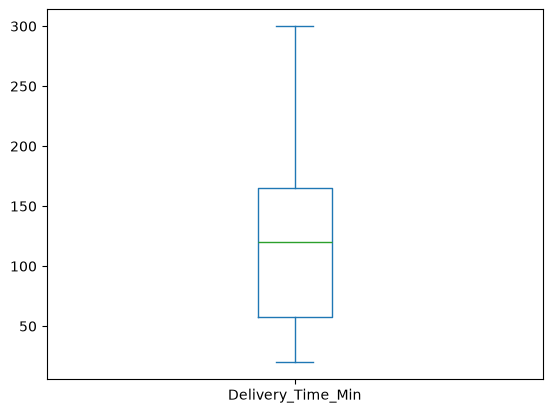

In [162]:
df["Delivery_Time_Min"].plot(kind="box")

<Axes: >

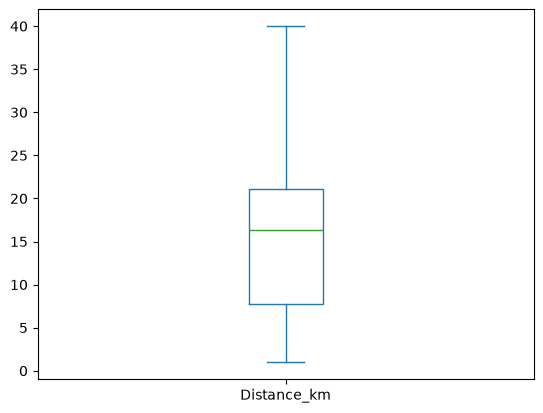

In [163]:
df["Distance_km"].plot(kind="box")

<Axes: >

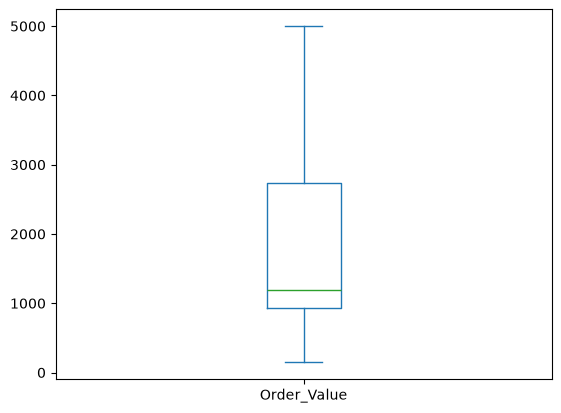

In [164]:
df["Order_Value"].plot(kind="box")

<Axes: >

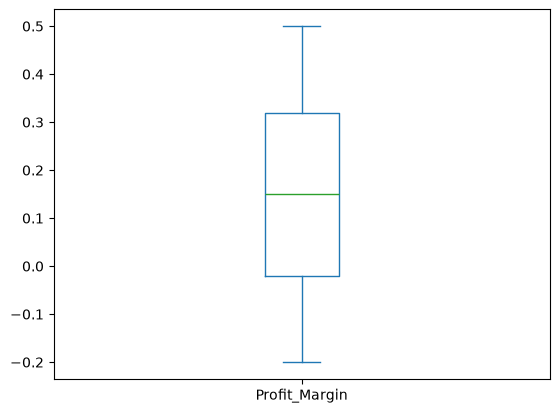

In [165]:
df['Profit_Margin'].plot(kind="box")

In [166]:
df["Delivery_Time_Min"].quantile([0.90, 0.95, 0.99])

0.90    246
0.95    273
0.99    295
Name: Delivery_Time_Min, dtype: Int64

<Axes: >

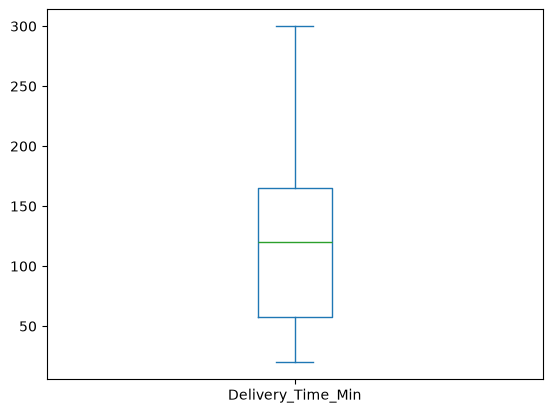

In [167]:
df["Delivery_Time_Min"].plot(kind="box")

In [168]:
Q1 = df["Delivery_Time_Min"].quantile(0.25)
Q3 = df["Delivery_Time_Min"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Limit:", lower)
print("Upper Limit:", upper)

print("Outliers:",
      ((df["Delivery_Time_Min"] < lower) |
       (df["Delivery_Time_Min"] > upper)).sum())

Lower Limit: -102.5
Upper Limit: 325.5
Outliers: 0


In [169]:
outlier_cols = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Final_Amount"
]

df[outlier_cols].describe()

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Final_Amount
count,100000.0,84964.0,100000.000000,100000.00000,100000.000000
mean,38.99463,119.668942,16.449519,1786.94279,1709.302560
std,12.364352,76.248493,9.997431,1335.39821,1338.752465
min,18.0,20.0,1.000000,150.00000,0.000000
25%,28.0,58.0,7.760000,935.00000,856.000000
50%,39.0,120.0,16.390000,1197.00000,1177.000000
75%,50.0,165.0,21.130000,2743.00000,2663.000000
max,60.0,300.0,40.000000,5000.00000,5000.000000


In [170]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    print("\n", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)


 Customer_Age
Q1: 28.0
Q3: 50.0
IQR: 22.0
Lower Limit: -5.0
Upper Limit: 83.0

 Delivery_Time_Min
Q1: 58
Q3: 165
IQR: 107
Lower Limit: -102.5
Upper Limit: 325.5

 Distance_km
Q1: 7.76
Q3: 21.13
IQR: 13.37
Lower Limit: -12.295
Upper Limit: 41.185

 Order_Value
Q1: 935.0
Q3: 2743.0
IQR: 1808.0
Lower Limit: -1777.0
Upper Limit: 5455.0

 Final_Amount
Q1: 856.0
Q3: 2663.0
IQR: 1807.0
Lower Limit: -1854.5
Upper Limit: 5373.5


# CORRELATION ANALYSIS

In [171]:
df.select_dtypes(include='number').columns
df.nunique()       

Order_ID               100000
Customer_ID              8999
Customer_Age               43
Customer_Gender             4
City                        6
Area                        6
Restaurant_ID             900
Restaurant_Name           500
Cuisine_Type                6
Order_Date                365
Order_Time                  1
Delivery_Time_Min         232
Distance_km              3402
Order_Value              4052
Discount_Applied          154
Final_Amount             4475
Payment_Mode                5
Order_Status                2
Cancellation_Reason         5
Delivery_Partner_ID       900
Delivery_Rating             5
Restaurant_Rating          21
Order_Day                   2
Peak_Hour                   3
Profit_Margin              71
Is_Loss                     2
dtype: int64

In [172]:
df[numeric_cols].columns

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Is_Loss'],
      dtype='str')

In [173]:
num_cont_col=['Delivery_Time_Min', 'Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount', 'Profit_Margin', 'Restaurant_Rating']

In [174]:
num_dis_cols=['Customer_Age', 'Delivery_Rating', 'Order_Month', 'Is_Loss']

In [175]:
numeric_cols = df.select_dtypes(include="number").columns

correlation = df[numeric_cols].corr()

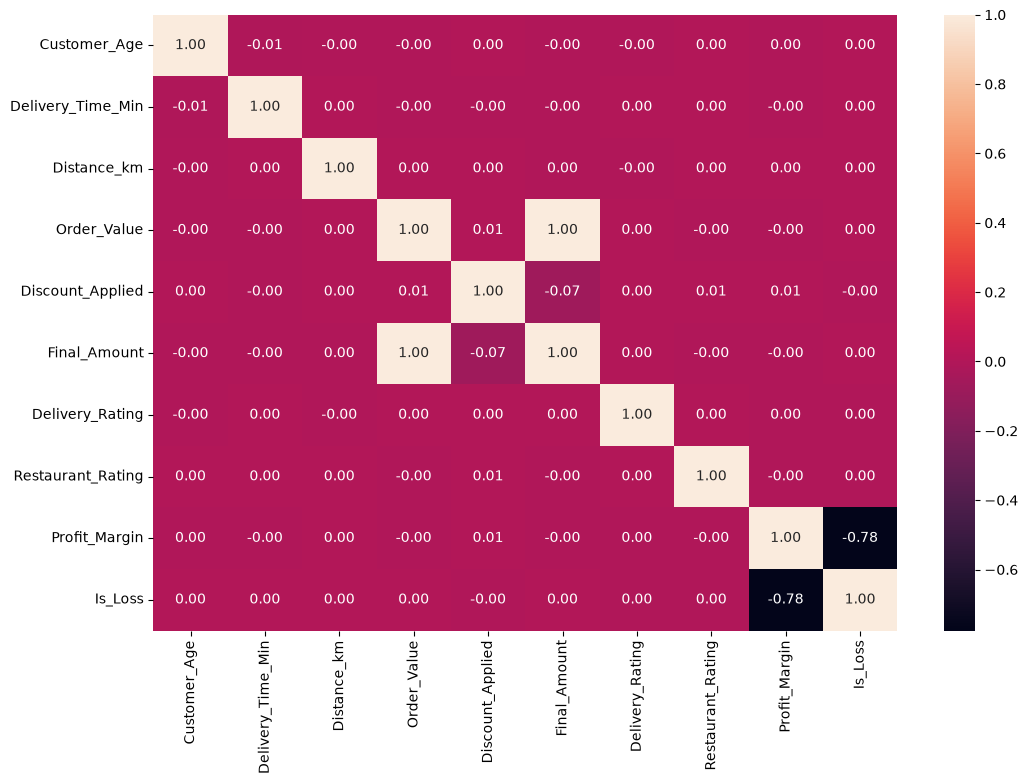

In [176]:
numeric_cols = df.select_dtypes(
    include=["number"]
).columns

corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f")
plt.show()

 UNIVARIATE

NUMERICAL COLUMNS

In [177]:
df[numeric_cols].columns

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Is_Loss'],
      dtype='str')

In [178]:
df.groupby("Discount_Applied")["Profit_Margin"].mean()

Discount_Applied
0.0      0.150087
20.0     0.149466
50.0     0.148529
100.0    0.151326
150.0    0.300000
           ...   
296.0    0.276667
297.0    0.296667
298.0    0.115000
299.0    0.450000
300.0    0.152895
Name: Profit_Margin, Length: 154, dtype: float64

In [179]:
df[numeric_cols]['Customer_Age'].describe()

count     100000.0
mean      38.99463
std      12.364352
min           18.0
25%           28.0
50%           39.0
75%           50.0
max           60.0
Name: Customer_Age, dtype: Float64

CATEGORICAL COLUMNS

In [180]:
print(categorical_cols)

['Customer_Gender', 'City', 'Area', 'Cuisine_Type', 'Payment_Mode', 'Order_Status', 'Cancellation_Reason', 'Order_Day', 'Peak_Hour']


In [181]:
categorical_cols = df.select_dtypes(include=['str']).columns

for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())



Value counts for Order_ID:
Order_ID
ORD000001    1
ORD000002    1
ORD000003    1
ORD000004    1
ORD000005    1
            ..
ORD099996    1
ORD099997    1
ORD099998    1
ORD099999    1
ORD100000    1
Name: count, Length: 100000, dtype: int64

Value counts for Customer_ID:
Customer_ID
CUST2487    24
CUST4431    23
CUST7657    23
CUST7842    23
CUST9262    23
            ..
CUST8726     1
CUST7120     1
CUST8380     1
CUST5157     1
CUST4958     1
Name: count, Length: 8999, dtype: int64

Value counts for Customer_Gender:
Customer_Gender
Other      25135
Female     25031
Male       24978
Unknown    24856
Name: count, dtype: int64

Value counts for City:
City
Hyderabad    16884
Bangalore    16732
Unknown      16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64

Value counts for Area:
Area
South      16725
Unknown    16685
North      16675
West       16653
East       16643
Central    16619
Name: count, dtype: int64

Value counts for Restaurant_ID:
Rest

EDA- Target- Order_Values

1. DISTRIBUTION OF ORDER VALUES-UNIVARIATE ANALYSIS-

Understand how order values are distributed.

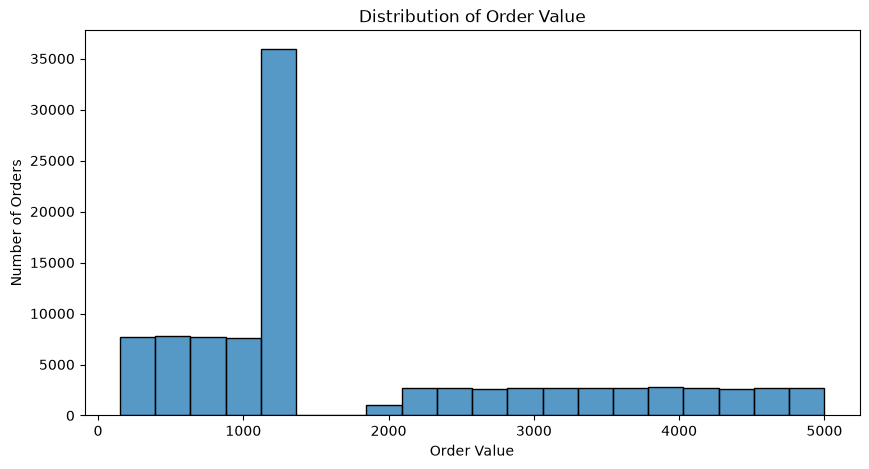

In [182]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x="Order_Value", bins=20)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

The distribution of order values was analyzed to understand customer spending behavior and identify the concentration and spread of order values

2. DISTRIBUTION OF DELIVERY TIME -UNIVARIATE-

Understand typical delivery duration and identify unusually long deliveries.

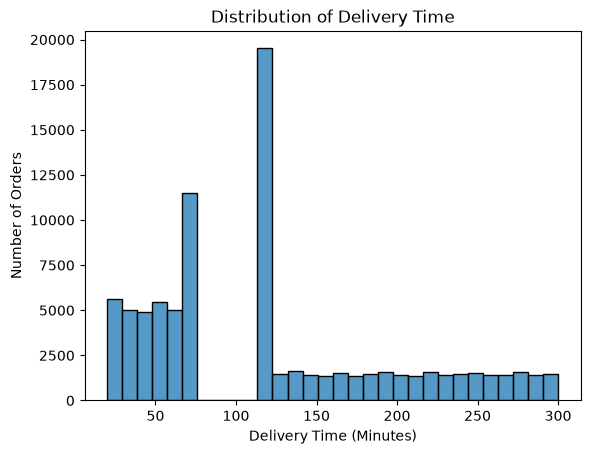

In [183]:
sns.histplot(data=df, x="Delivery_Time_Min", bins=30)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")
plt.show()

3. CITY WISE ORDER ANALYSIS--UNIVARIATE
Identify cities generating the highest number of orders

Categorical Univariate Analysis

In [184]:
df['City'].value_counts()
city_orders = df["City"].value_counts()

print(city_orders)

City
Hyderabad    16884
Bangalore    16732
Unknown      16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


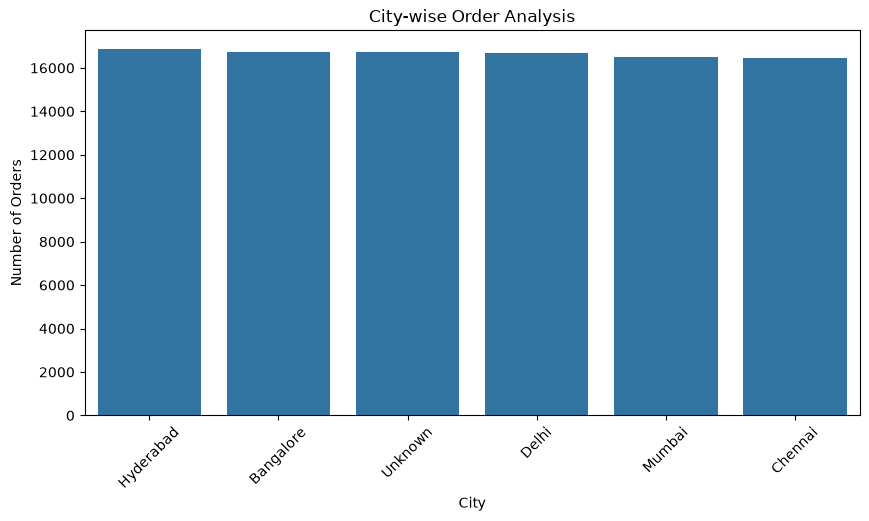

In [185]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="City",
    order=df["City"].value_counts().index
)

plt.title("City-wise Order Analysis")
plt.xlabel("City")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

City-wise order analysis was performed to identify geographical differences in order demand.

4. CUISINE WISE ORDER ANALYSIS-UNIVARIATE 
Identify the most popular cuisine types.

In [186]:
df['Cuisine_Type'].value_counts()

Cuisine_Type
Unknown    16885
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64

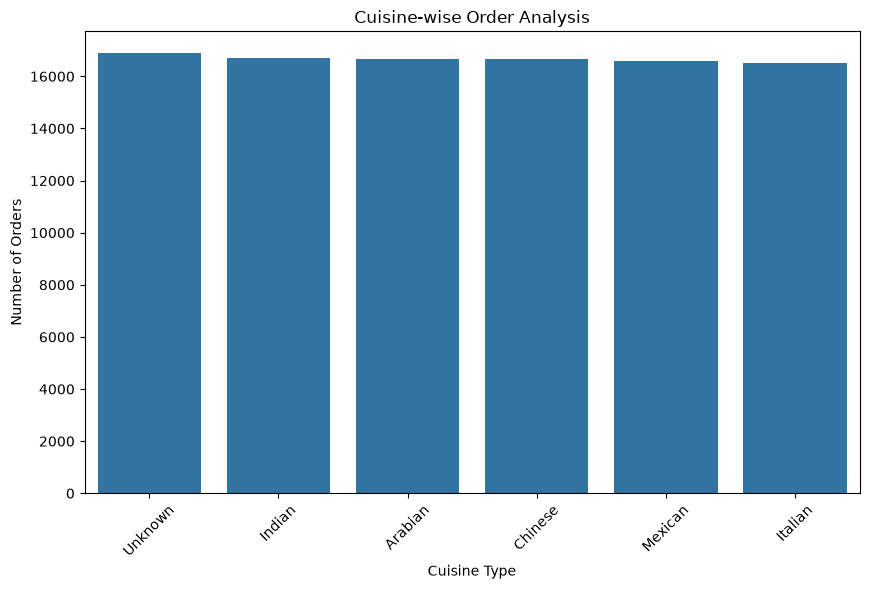

In [187]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Cuisine_Type",
    order=df["Cuisine_Type"].value_counts().index
)

plt.title("Cuisine-wise Order Analysis")
plt.xlabel("Cuisine Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

Cuisine-wise analysis was performed to identify customer preferences and determine which cuisine types generate the highest order demand.

5. WEEKEND VS WEEKDAY DEMAND -  UNIVARIATE Categorical analysis

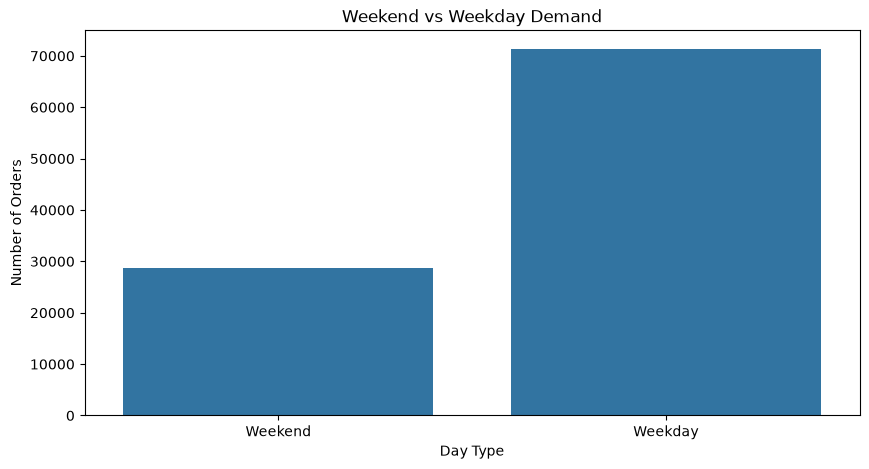

In [188]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Order_Day")

plt.title("Weekend vs Weekday Demand")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.show()

Weekend and weekday order demand was compared to identify differences in customer ordering patterns across day types.

6. DISTANCE VS DELIVERY DELAY- BIVARIATE
Relationship Between Distance and Delivery Time

Both are Numerical continuous

In [189]:
df[["Distance_km", "Delivery_Time_Min"]].corr()

,Distance_km,Delivery_Time_Min
Distance_km,1.000000,0.004345
Delivery_Time_Min,0.004345,1.000000


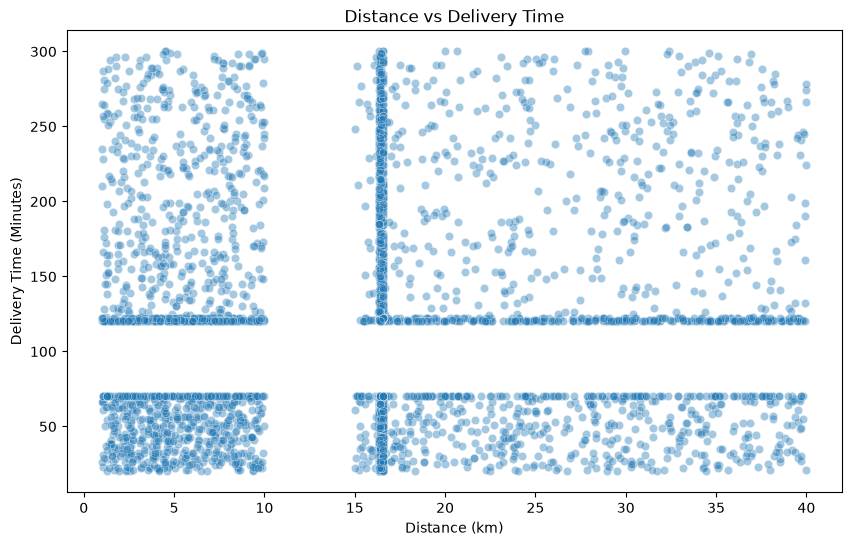

In [190]:
sample_df = df.sample(5000, random_state=42)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="Distance_km",
    y="Delivery_Time_Min",
    alpha=0.4
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

7. CANCELLATION REASONS - UNIVARIATE-Categorical


In [191]:
cancelled = df[df["Order_Status"].str.contains("cancel", case=False, na=False)]
reason_counts = cancelled["Cancellation_Reason"].value_counts()

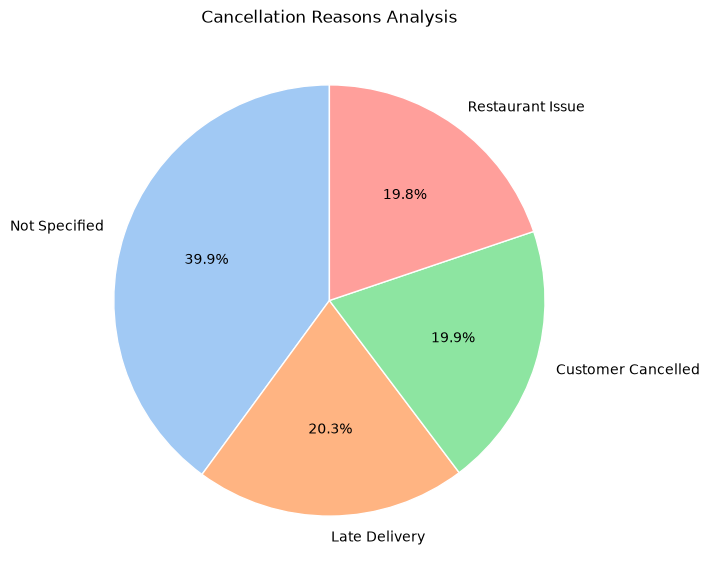

In [192]:
plt.figure(figsize=(7, 7))
plt.pie(reason_counts.values,
        labels=reason_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("pastel"),
        wedgeprops={"edgecolor": "white"})
plt.title("Cancellation Reasons Analysis")
plt.show()

Cancellation reason analysis was performed to identify the major factors contributing to cancelled orders and highlight areas for operational improvement

8. CORRELATION ANALSYSIS AMOUNG NUMERIC FEATURES- MULTIVARIATE

In [193]:
corr = df.select_dtypes(include="number").corr()
print(corr)

                   Customer_Age  Delivery_Time_Min  Distance_km  Order_Value  \
Customer_Age           1.000000          -0.008886    -0.001875    -0.002780   
Delivery_Time_Min     -0.008886           1.000000     0.004345    -0.000643   
Distance_km           -0.001875           0.004345     1.000000     0.000935   
Order_Value           -0.002780          -0.000643     0.000935     1.000000   
Discount_Applied       0.004012          -0.001942     0.003903     0.006513   
Final_Amount          -0.003084          -0.000490     0.000630     0.996989   
Delivery_Rating       -0.000141           0.002915    -0.000570     0.001273   
Restaurant_Rating      0.002144           0.002736     0.004025    -0.003619   
Profit_Margin          0.000088          -0.002674     0.001436    -0.002426   
Is_Loss                0.003906           0.001891     0.001113     0.004101   

                   Discount_Applied  Final_Amount  Delivery_Rating  \
Customer_Age               0.004012     -0.003084

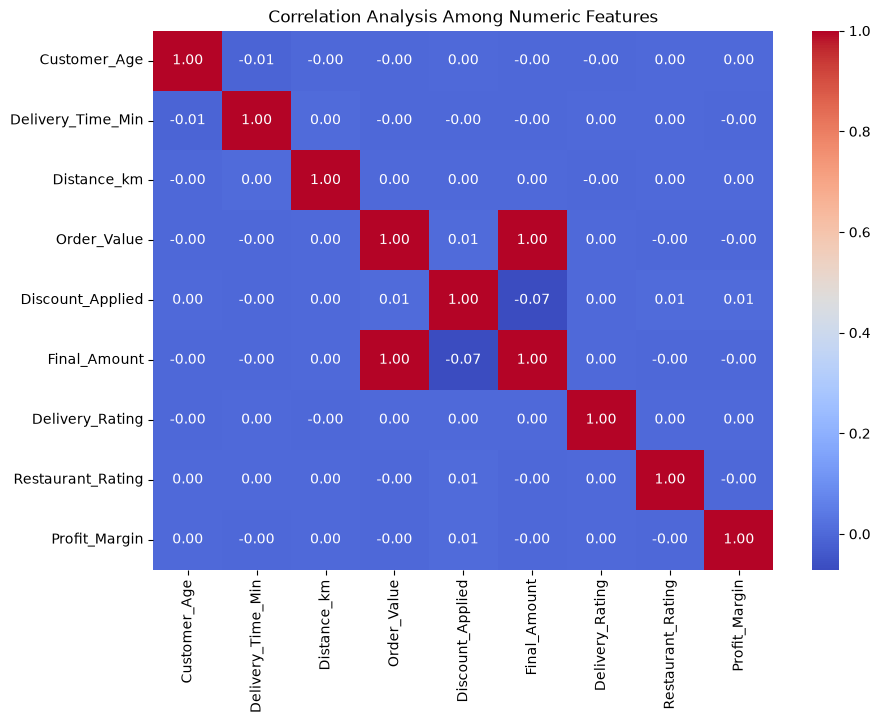

In [194]:
numeric_cols = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Final_Amount",
    "Delivery_Rating",
    "Restaurant_Rating",
    "Profit_Margin"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Analysis Among Numeric Features")
plt.show()

# FEATURE ENGINEERING

1. Order Day Type — Weekday / Weekend
Do customers place more orders on weekdays or weekends?

In [195]:
df["Order_Date"].dtype

dtype('<M8[us]')

In [196]:
df["Order_Day_Type"] = df["Order_Date"].dt.dayofweek.apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

In [197]:
df["Order_Day_Type"].value_counts()

Order_Day_Type
Weekday    71632
Weekend    28368
Name: count, dtype: int64

In [198]:
df[["Order_Date", "Order_Day_Type"]].head()

,Order_Date,Order_Day_Type
0,2024-10-20,Weekend
1,2024-08-12,Weekday
2,2024-12-08,Weekend
3,2024-10-08,Weekday
4,2024-02-04,Weekend


2. Peak hour indicator


In [199]:
df["Peak_Hour"].value_counts(dropna=False)

Peak_Hour
Off-Peak    33585
Peak        33453
Unknown     32962
Name: count, dtype: int64

3.Profit margin percentage

In [200]:
df["Profit_Margin_Percentage"] = (
    df["Profit_Margin"] * 100
)

In [201]:
df["Profit_Margin_Percentage"].describe()

count    100000.000000
mean         15.036200
std          20.188757
min         -20.000000
25%          -2.000000
50%          15.000000
75%          32.000000
max          50.000000
Name: Profit_Margin_Percentage, dtype: float64

In [202]:
df["Profit_Margin_Percentage"] = df["Profit_Margin"] * 100

In [203]:
print(df["Profit_Margin_Percentage"].describe())

count    100000.000000
mean         15.036200
std          20.188757
min         -20.000000
25%          -2.000000
50%          15.000000
75%          32.000000
max          50.000000
Name: Profit_Margin_Percentage, dtype: float64


In [204]:
df["Delivery_Performance"] = pd.cut(df["Delivery_Time_Min"], bins=[0, 30, 45, 1000],
    labels=["Fast", "On Time", "Delayed"])

4. Delivery Performance Category

In [205]:
df["Delivery_Performance"] = pd.cut(df["Delivery_Time_Min"],bins=[0, 30, 45, 1000],
     labels=["Fast", "On Time", "Delayed"])

In [206]:
df["Delivery_Performance"].value_counts()

Delivery_Performance
Delayed    70461
On Time     8357
Fast        6146
Name: count, dtype: int64

5.Customer age groups

In [207]:
df["Age_Group"] = pd.cut(df["Customer_Age"],bins=[0, 25, 35, 50, 100],
    labels=["Under 25", "25-35", "36-50", "Above 50"])

In [208]:
df["Age_Group"].value_counts()

Age_Group
36-50       35299
25-35       23130
Above 50    23017
Under 25    18554
Name: count, dtype: int64

In [209]:
df[[
    "Order_Day_Type",
    "Peak_Hour",
    "Profit_Margin_Percentage",
    "Delivery_Performance",
    "Age_Group"
    ]].head()

,Order_Day_Type,Peak_Hour,Profit_Margin_Percentage,Delivery_Performance,Age_Group
0,Weekend,Peak,13.0,Delayed,Under 25
1,Weekday,Peak,48.0,Fast,Above 50
2,Weekend,Peak,8.0,Delayed,36-50
3,Weekday,Unknown,4.0,NaN,25-35
4,Weekend,Off-Peak,12.0,Delayed,Above 50


In [214]:
df.to_csv("food_delivery.csv", index=False)

In [215]:
from sqlalchemy import create_engine

username = "postgres"
password = "Mls1102"
host = "localhost"
port = "5432"
database = "food_delivery"

DATABASE_URL = (
f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

engine = create_engine(DATABASE_URL)

with engine.connect() as connection:
    print("PostgreSQL connected successfully!")

PostgreSQL connected successfully!


In [ ]:
df.to_sql("food_delivery",engine,if_exists="replace", index=False
)

1000

In [217]:
result = pd.read_sql(
    "SELECT * FROM food_delivery LIMIT 10",
    engine
)

result

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin,Is_Loss,Order_Day_Type,Profit_Margin_Percentage,Delivery_Performance,Age_Group
0,ORD000001,CUST6948,19,Male,Unknown,Central,RES936,Restaurant_29,Chinese,2024-10-20,...,5.0,4.4,Weekend,Peak,0.13,0,Weekend,13.0,Delayed,Under 25
1,ORD000002,CUST6515,54,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,...,5.0,4.7,Weekday,Peak,0.48,0,Weekday,48.0,Fast,Above 50
2,ORD000003,CUST1765,46,Male,Delhi,Unknown,RES723,Restaurant_244,Arabian,2024-12-08,...,4.0,4.9,Weekend,Peak,0.08,0,Weekend,8.0,Delayed,36-50
3,ORD000004,CUST2744,32,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,...,NaN,3.4,Weekday,Unknown,0.04,0,Weekday,4.0,NaN,25-35
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,...,2.0,4.4,Weekend,Off-Peak,0.12,0,Weekend,12.0,Delayed,Above 50
5,ORD000006,CUST3161,37,Other,Chennai,East,RES810,Restaurant_153,Mexican,2024-07-09,...,3.0,4.6,Weekday,Peak,0.24,0,Weekday,24.0,Delayed,36-50
6,ORD000007,CUST2307,40,Other,Delhi,Unknown,RES333,Restaurant_302,Chinese,2024-02-14,...,2.0,4.5,Weekday,Unknown,0.02,0,Weekday,2.0,Delayed,36-50
7,ORD000008,CUST5865,46,Male,Unknown,North,RES696,Restaurant_41,Chinese,2024-05-26,...,5.0,3.8,Weekend,Unknown,0.18,0,Weekend,18.0,Delayed,36-50
8,ORD000009,CUST4356,24,Other,Delhi,Central,RES780,Restaurant_155,Italian,2024-09-07,...,2.0,3.7,Weekend,Peak,0.08,0,Weekend,8.0,Delayed,Under 25
9,ORD000010,CUST2404,49,Female,Unknown,South,RES155,Restaurant_368,Chinese,2024-01-22,...,4.0,4.5,Weekday,Peak,0.03,0,Weekday,3.0,Delayed,36-50
